# Phase 1 — Data (in-sample only)

Pair **INTC (A) / AMD (B)**, daily adjusted prices from Yahoo Finance (`auto_adjust=True`, i.e. adjusted for splits and dividends).

**Only dates < 2013-01-01 (in-sample).** No later data is loaded: the cut happens inside `load_pair(end=SPLIT_DATE)`, right after reading the file. The full-history version of this phase will be generated only after the single out-of-sample run (see `EXPERIMENTS.md`).

Charts are saved in `reports/figures/` as both HTML (interactive) and PNG; below they are shown as static PNGs, because GitHub does not render Plotly charts.

In [1]:
import logging
import math

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.config import SPLIT_DATE, TICKER_A, TICKER_B
from pairs.data import daily_returns, load_pair, return_correlation_table
from pairs.plotting import DERIVED_COLOR, SERIES_COLORS, apply_style, save_figure

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
# Silence the per-export INFO chatter of kaleido's headless-Chrome driver.
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

In [2]:
prices = load_pair(end=SPLIT_DATE)

assert prices.index.max() < pd.Timestamp(SPLIT_DATE), "out-of-sample date leaked"
assert len(prices) == 8273, "must match the IS day count in EXPERIMENTS.md"
print(
    f"{len(prices)} common trading days, {prices.index.min().date()} -> {prices.index.max().date()}"
)

INFO pairs.data: Loaded INTC/AMD: 8273 common days, 1980-03-17 -> 2012-12-31 (end=2013-01-01, exclusive)


8273 common trading days, 1980-03-17 -> 2012-12-31


## a) Both prices, log scale

On a log scale the same vertical distance corresponds to the same *percentage* change: needed because over 33 years prices change by orders of magnitude.

INFO pairs.plotting: Saved figure 01a_prices_log_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


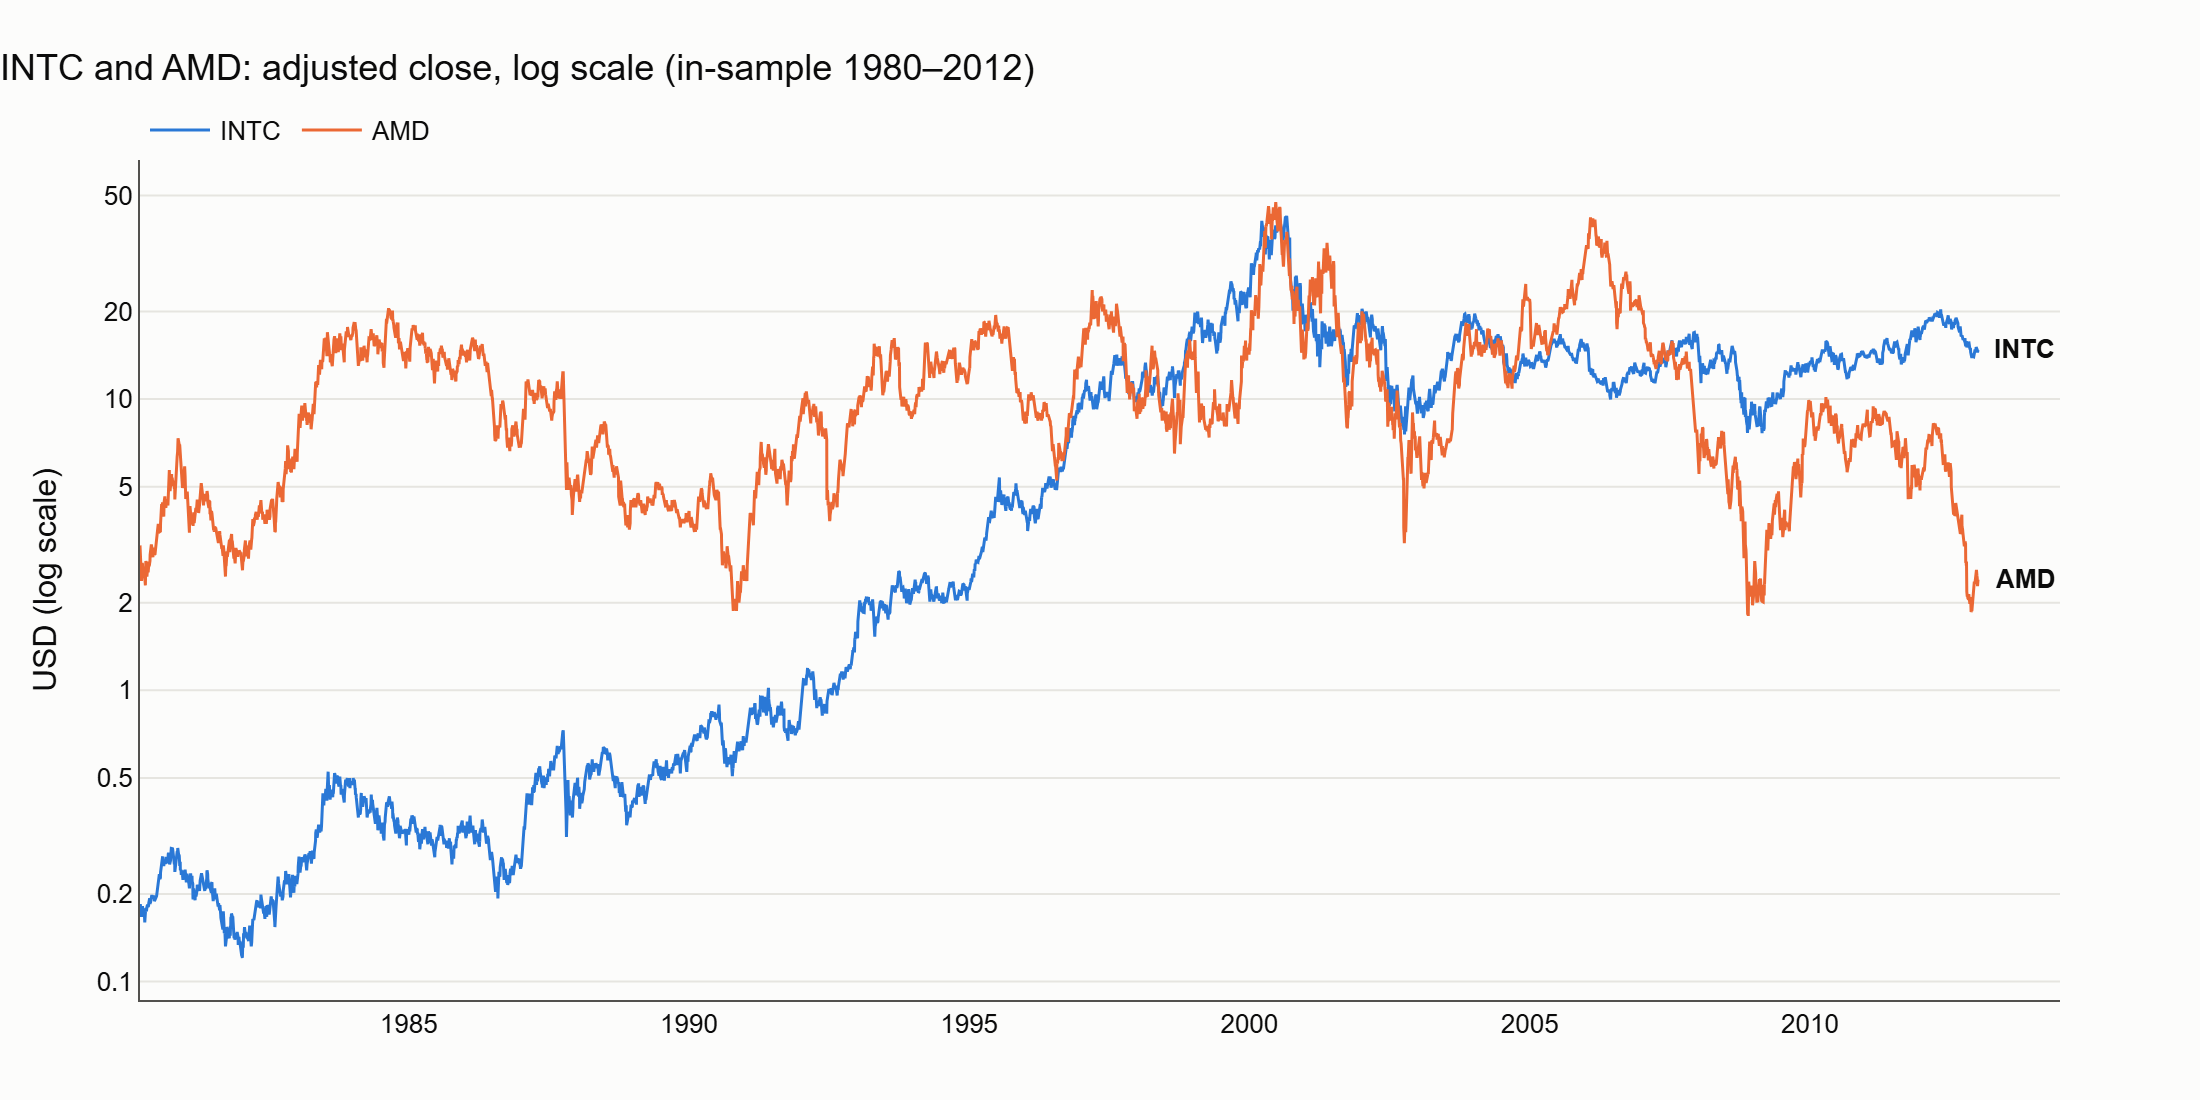

In [3]:
fig = go.Figure()
for t in (TICKER_A, TICKER_B):
    fig.add_trace(
        go.Scatter(
            x=prices.index,
            y=prices[t],
            name=t,
            mode="lines",
            line={"color": SERIES_COLORS[t], "width": 1.5},
        )
    )
    # On a log axis Plotly expects annotation y in log10 units.
    fig.add_annotation(
        x=prices.index[-1],
        y=math.log10(prices[t].iloc[-1]),
        text=f"<b>{t}</b>",
        xanchor="left",
        showarrow=False,
        xshift=6,
        font={"size": 13},
    )
apply_style(fig, "INTC and AMD: adjusted close, log scale (in-sample 1980–2012)")
fig.update_yaxes(
    type="log", tickvals=[0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50], title_text="USD (log scale)"
)
fig.update_layout(margin={"r": 70})

_, png = save_figure(fig, "01a_prices_log_is")
display(Image(filename=png))

## b) INTC/AMD ratio and INTC − AMD difference

Two separate panels, because the two quantities have different units (pure number and dollars). The ratio is on a log scale: a doubling and a halving have the same height.

INFO pairs.plotting: Saved figure 01b_ratio_difference_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


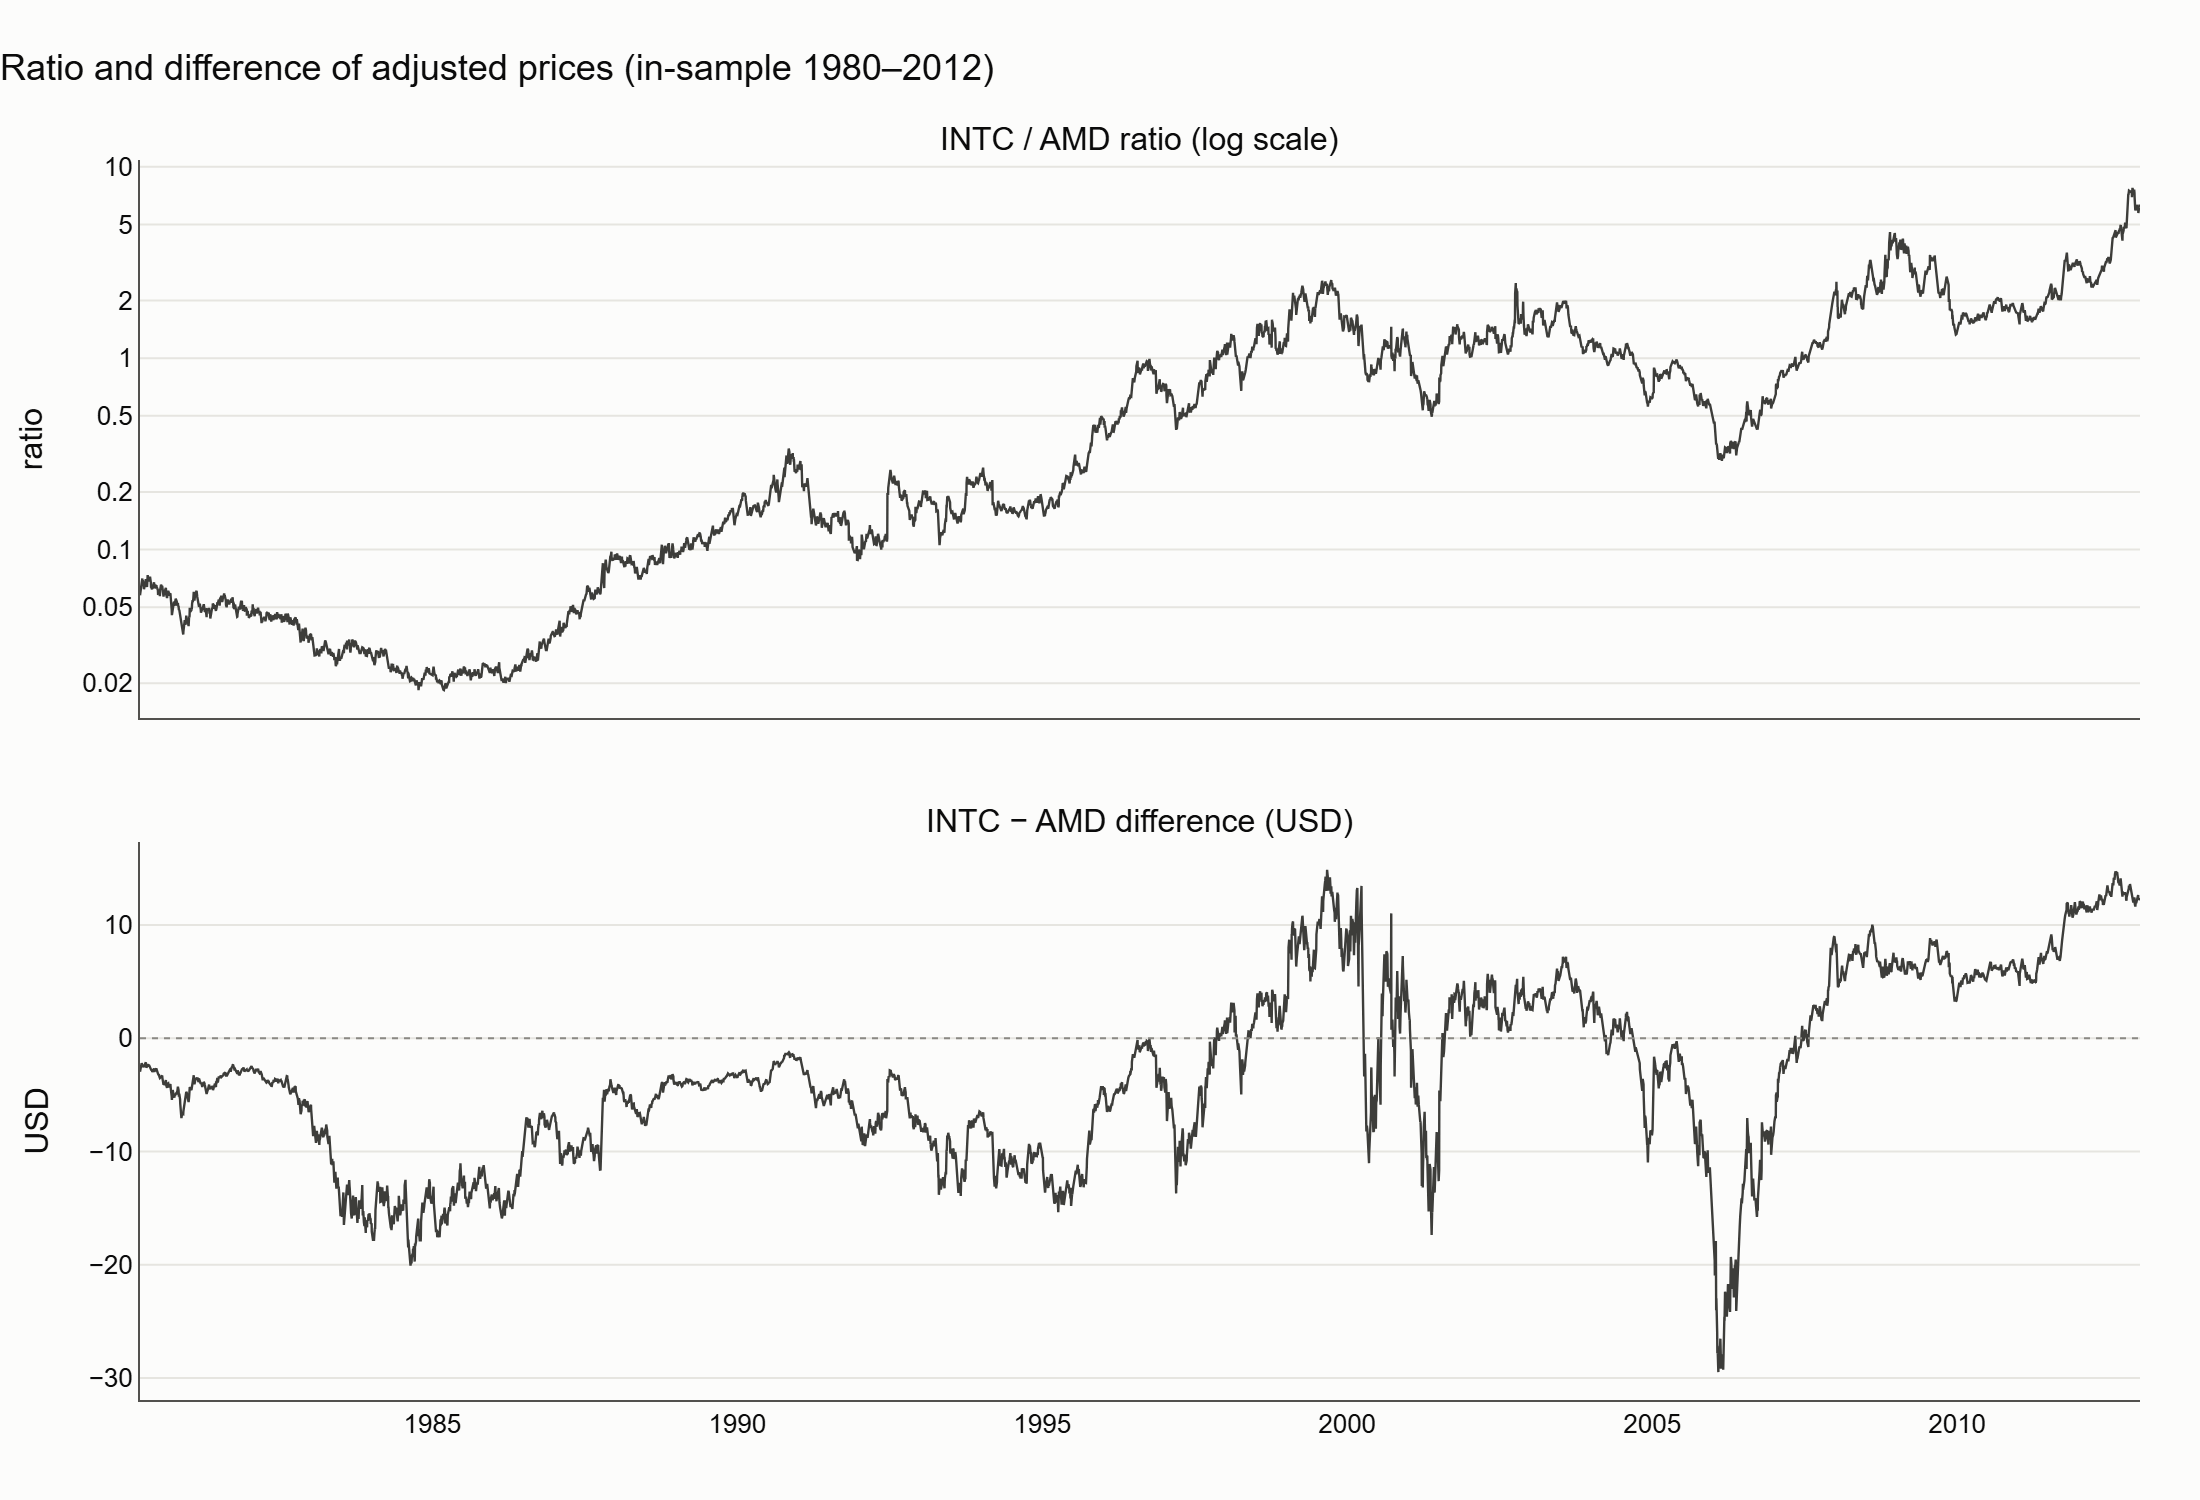

,date,ratio
start,1980-03-17,0.058
min,1984-10-10,0.018
max,2012-11-16,7.763
end,2012-12-31,6.144


In [4]:
ratio = prices[TICKER_A] / prices[TICKER_B]
diff = prices[TICKER_A] - prices[TICKER_B]

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.10,
    subplot_titles=("INTC / AMD ratio (log scale)", "INTC − AMD difference (USD)"),
)
line = {"color": DERIVED_COLOR, "width": 1.2}
fig.add_trace(go.Scatter(x=ratio.index, y=ratio, name="INTC / AMD", line=line), row=1, col=1)
fig.add_trace(go.Scatter(x=diff.index, y=diff, name="INTC − AMD", line=line), row=2, col=1)
fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"}, row=2, col=1)
apply_style(fig, "Ratio and difference of adjusted prices (in-sample 1980–2012)")
fig.update_layout(showlegend=False)
fig.update_yaxes(
    type="log",
    title_text="ratio",
    row=1,
    col=1,
    tickvals=[0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10],
)
fig.update_yaxes(title_text="USD", row=2, col=1)

_, png = save_figure(fig, "01b_ratio_difference_is", height=750)
display(Image(filename=png))

# Where the ratio starts, ends and its extremes (numbers quoted in the notes below).
pd.DataFrame(
    {
        "date": [ratio.index[0], ratio.idxmin(), ratio.idxmax(), ratio.index[-1]],
        "ratio": [ratio.iloc[0], ratio.min(), ratio.max(), ratio.iloc[-1]],
    },
    index=["start", "min", "max", "end"],
).assign(date=lambda d: d["date"].dt.date).round(3)

## c) Correlation of daily returns

Simple return $r_t = P_t / P_{t-1} - 1$, computed between consecutive common trading days. Pearson correlation over the whole in-sample period and by decade (1980 starts in March, the 2010s cover only 2010–2012).

In [5]:
returns = daily_returns(prices)
corr_table = return_correlation_table(returns)

assert corr_table.loc["All", "n_days"] == len(prices) - 1
corr_table.round({"correlation": 3})

,start,end,n_days,correlation
period,,,,
All,1980-03-18,2012-12-31,8272,0.483
1980s,1980-03-18,1989-12-29,2475,0.557
1990s,1990-01-02,1999-12-31,2528,0.330
2000s,2000-01-03,2009-12-31,2515,0.545
2010s,2010-01-04,2012-12-31,754,0.585


## Observations (in-sample only, no Phase 2 parameter chosen here)

- **Prices.** The two series do not move at a constant ratio: INTC grows almost steadily until 2000, while AMD swings in wide cycles with deep crashes (1990, 2002, 2008, 2012). They move together mainly in 1997–2005.
- **INTC/AMD ratio.** It has no stable level: it starts at 0.058 (1980), hits its minimum of 0.018 (1984-10-10) and its maximum of 7.763 (2012-11-16), and ends at 6.144. It shows long trending regimes (up 1985–2000, down 2000–2006, up 2006–2012) rather than oscillations around a mean.
- **INTC − AMD difference.** It crosses zero several times, but with excursions lasting years; in dollars its amplitude depends on the price level (in 1980 both were worth a few adjusted dollars), so it is not comparable over time.
- **Dividends.** INTC paid 81 dividends from 1992-10-26 to 2012, AMD none: INTC's adjusted price includes dividends, which adds a mechanical upward drift to the ratio.
- **Correlation of daily returns.** 0.483 over the whole in-sample period; by decade 0.557 (1980s), 0.330 (1990s), 0.545 (2000s), 0.585 (2010–2012). Always positive and moderate, with a clear dip in the 1990s.
- **Caveat:** a positive correlation of returns says that the two stocks move together *day by day*, not that their price *levels* return to a fixed relationship. The latter (a stationary spread) is what Phase 2 needs, and the ratio and difference charts suggest it does not hold in a stable way over 33 years. It must be tested in Phases 2 and 3, not assumed.